In [12]:
from IPython.display import display
import re
import string
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate, learning_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('vader_lexicon')

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

/home/ubuntu/.local/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/ubuntu/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package stopwords to /home/ubuntu/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/ubuntu/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/ubuntu/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [13]:
# Data Exploration

df = pd.read_csv("twitter_disaster.csv")

print("Dataset Shape:", df.shape)
print("\n Column Information:")
df.info()
df.head()

Dataset Shape: (7613, 5)

 Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7613 non-null   int64
 1   keyword   7552 non-null   str  
 2   location  5079 non-null   str  
 3   text      7613 non-null   str  
 4   target    7613 non-null   int64
dtypes: int64(2), str(3)
memory usage: 1.2 MB


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


=== Missing Value Summary ===
          Missing Count  Missing Percentage (%)
id                    0                    0.00
keyword              61                    0.80
location           2534                   33.29
text                  0                    0.00
target                0                    0.00


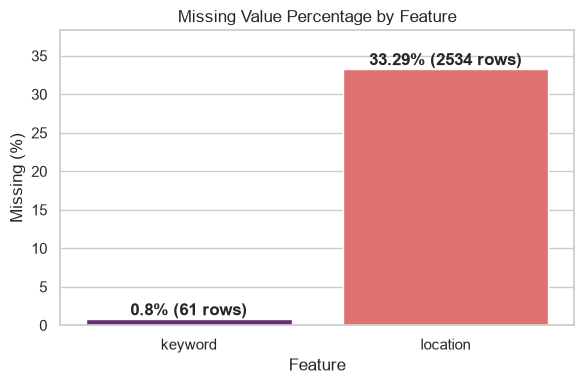


=== Duplicate Analysis ===
Total exact row duplicates: 0
Duplicate tweet texts: 110
Total rows with repeated tweet text: 179
Unique tweet texts with conflicting target labels: 18

Sample duplicate tweets with conflicting target labels:
  id  target                                                                                                                                       text
6094       0 #Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect
6105       0 #Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect
6123       1 #Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect
5996       1                      #foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #humanconsumption
602

In [14]:
# Missing Value & Duplicate Analysis

# 1. Missing Values Analysis
print("=== Missing Value Summary ===")
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_pct
})
print(missing_summary)

# Visualize Missing Values
missing_cols = missing_summary[missing_summary['Missing Count'] > 0]
if not missing_cols.empty:
    plt.figure(figsize=(6, 4))
    sns.barplot(x=missing_cols.index, y=missing_cols['Missing Percentage (%)'], hue=missing_cols.index, palette='magma', legend=False)
    plt.title("Missing Value Percentage by Feature")
    plt.xlabel("Feature")
    plt.ylabel("Missing (%)")
    for i, v in enumerate(missing_cols['Missing Percentage (%)']):
        plt.text(i, v + 0.5, f"{v}% ({missing_cols['Missing Count'].iloc[i]} rows)", ha='center', fontweight='bold')
    plt.ylim(0, max(missing_cols['Missing Percentage (%)']) + 5)
    plt.tight_layout()
    plt.show()

# 2. Duplicate Analysis
print("\n=== Duplicate Analysis ===")
exact_dupes = df.duplicated().sum()
text_dupes = df.duplicated(subset=['text']).sum()
total_repeated = df.duplicated(subset=['text'], keep=False).sum()

print(f"Total exact row duplicates: {exact_dupes}")
print(f"Duplicate tweet texts: {text_dupes}")
print(f"Total rows with repeated tweet text: {total_repeated}")

# Check duplicate tweets with conflicting target labels
repeated_df = df[df.duplicated(subset=['text'], keep=False)].sort_values('text')
label_counts_per_text = repeated_df.groupby('text')['target'].nunique()
conflicting_texts = label_counts_per_text[label_counts_per_text > 1]

print(f"Unique tweet texts with conflicting target labels: {len(conflicting_texts)}")

if len(conflicting_texts) > 0:
    print("\nSample duplicate tweets with conflicting target labels:")
    sample_conflicts = repeated_df[repeated_df['text'].isin(conflicting_texts.index[:3])][['id', 'target', 'text']]
    print(sample_conflicts.to_string(index=False))


target
0    0.57034
1    0.42966
Name: proportion, dtype: float64


/tmp/ipykernel_69302/3615917304.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, palette='viridis')


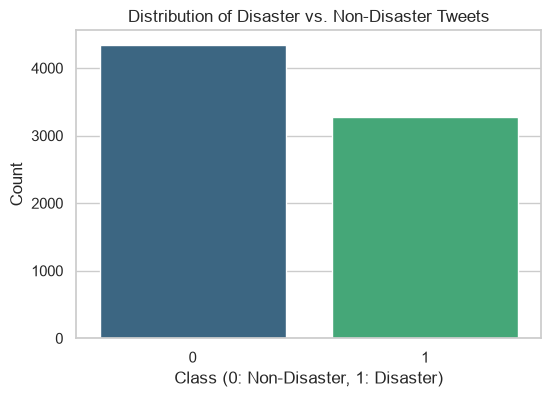

In [15]:
#Target Class Distribution

target_col = 'target' # 1 = Disaster, 0 = Non-disaster

print(df[target_col].value_counts(normalize=True))

plt.figure(figsize=(6,4))
sns.countplot(x=target_col, data=df, palette='viridis')
plt.title("Distribution of Disaster vs. Non-Disaster Tweets")
plt.xlabel("Class (0: Non-Disaster, 1: Disaster)")
plt.ylabel("Count")
plt.show()

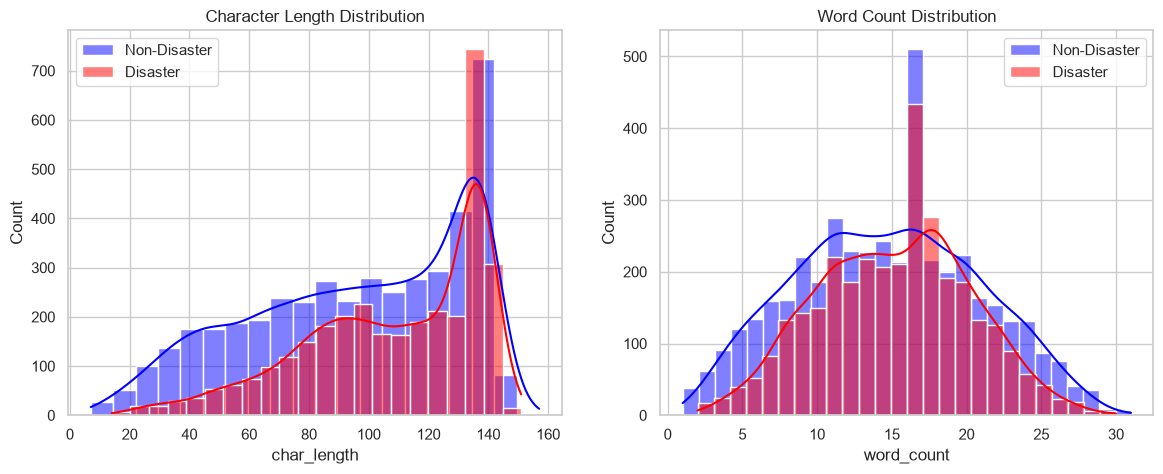

In [16]:
# Metadata Features Exploration (Tweet Length & Word Count)

text_col = 'text'

# Length of tweets'word_count
df['char_length'] = df[text_col].astype(str).apply(len)
df['word_count'] = df[text_col].astype(str).apply(lambda x: len(x.split()))

fig, axes =plt.subplots(1,2, figsize=(14,5))
sns.histplot(df[df[target_col] == 0]['char_length'], color='blue', label='Non-Disaster', kde=True, ax=axes[0])
sns.histplot(df[df[target_col] == 1]['char_length'], color='red', label='Disaster', kde=True, ax=axes[0])
axes[0].set_title('Character Length Distribution')
axes[0].legend()

sns.histplot(df[df[target_col] == 0]['word_count'], color='blue', label='Non-Disaster', kde=True, ax=axes[1])
sns.histplot(df[df[target_col] == 1]['word_count'], color='red', label='Disaster', kde=True, ax=axes[1])
axes[1].set_title("Word Count Distribution")
axes[1].legend()
plt.show()

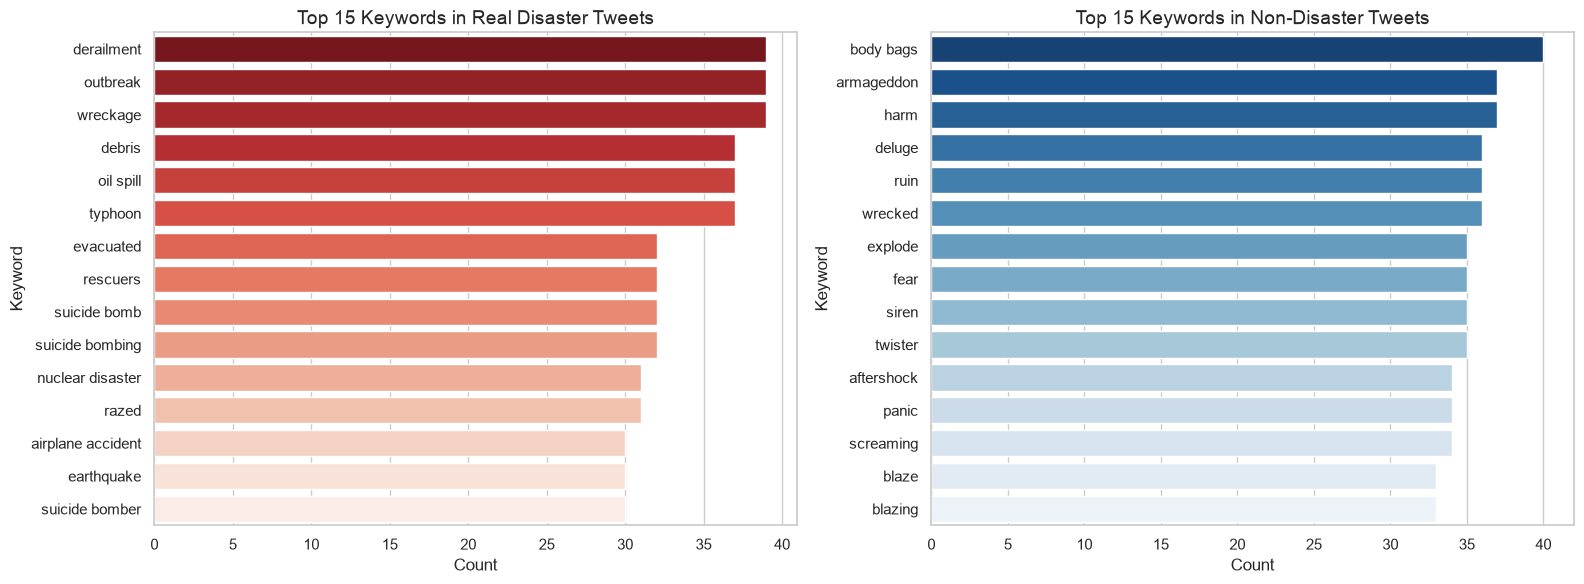

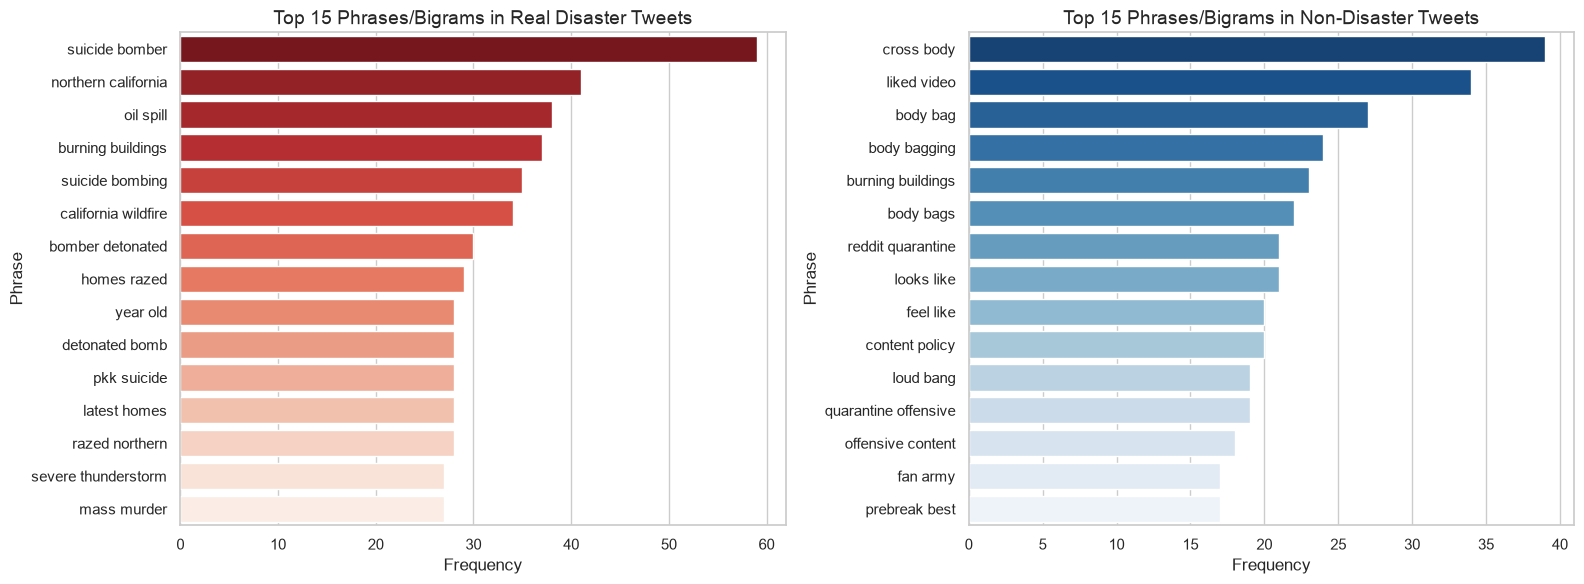

Top 5 Disaster Keywords: ['derailment', 'outbreak', 'wreckage', 'debris', 'oil spill']
Top 5 Disaster Phrases : ['suicide bomber', 'northern california', 'oil spill', 'burning buildings', 'suicide bombing']


In [17]:
# Keyword and Phrase Frequency Analysis

import re
from urllib.parse import unquote
from sklearn.feature_extraction.text import CountVectorizer

top_n = 15

# --- 1. Keyword Frequency Analysis (from 'keyword' column) ---
kw_clean = df['keyword'].dropna().apply(unquote)
disaster_kw = kw_clean[df[target_col] == 1].value_counts().head(top_n)
nondisaster_kw = kw_clean[df[target_col] == 0].value_counts().head(top_n)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=disaster_kw.values, y=disaster_kw.index, ax=axes[0], palette='Reds_r', hue=disaster_kw.index, legend=False)
axes[0].set_title(f"Top {top_n} Keywords in Real Disaster Tweets", fontsize=14)
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Keyword")

sns.barplot(x=nondisaster_kw.values, y=nondisaster_kw.index, ax=axes[1], palette='Blues_r', hue=nondisaster_kw.index, legend=False)
axes[1].set_title(f"Top {top_n} Keywords in Non-Disaster Tweets", fontsize=14)
axes[1].set_xlabel("Count")
axes[1].set_ylabel("Keyword")
plt.tight_layout()
plt.show()

# --- 2. Phrase / Bigram Frequency Analysis (from tweet text) ---
def clean_for_bigrams(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    return text

cleaned_for_phrases = df[text_col].apply(clean_for_bigrams)
vec = CountVectorizer(ngram_range=(2, 2), stop_words='english', token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')

dis_matrix = vec.fit_transform(cleaned_for_phrases[df[target_col] == 1])
dis_phrases = pd.Series(dis_matrix.toarray().sum(axis=0), index=vec.get_feature_names_out()).sort_values(ascending=False).head(top_n)

vec_non = CountVectorizer(ngram_range=(2, 2), stop_words='english', token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
nondis_matrix = vec_non.fit_transform(cleaned_for_phrases[df[target_col] == 0])
nondis_phrases = pd.Series(nondis_matrix.toarray().sum(axis=0), index=vec_non.get_feature_names_out()).sort_values(ascending=False).head(top_n)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=dis_phrases.values, y=dis_phrases.index, ax=axes[0], palette='Reds_r', hue=dis_phrases.index, legend=False)
axes[0].set_title(f"Top {top_n} Phrases/Bigrams in Real Disaster Tweets", fontsize=14)
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Phrase")

sns.barplot(x=nondis_phrases.values, y=nondis_phrases.index, ax=axes[1], palette='Blues_r', hue=nondis_phrases.index, legend=False)
axes[1].set_title(f"Top {top_n} Phrases/Bigrams in Non-Disaster Tweets", fontsize=14)
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Phrase")
plt.tight_layout()
plt.show()

print("Top 5 Disaster Keywords:", list(disaster_kw.index[:5]))
print("Top 5 Disaster Phrases :", list(dis_phrases.index[:5]))


In [18]:
# Data Clearing and Text Preprocessing

stop_words = set(stopwords.words('english'))

def clean_tweet(text):
    if not isinstance(text, str):
        return ""

    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+','',text)
    text = re.sub(r'<.*?>','', text)

    text = re.sub(r'@\w+','',text)
    text = re.sub(r'#','',text)

    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\d+','',text)

    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words and len(word) > 2]
    return " ".join(tokens)

df['cleaned_text'] = df[text_col].apply(clean_tweet)
df[['text','cleaned_text',target_col]].head()


,text,cleaned_text,target
0,Our Deeds are the Reason of this #earthquake M...,deeds reason earthquake may allah forgive,1
1,Forest fire near La Ronge Sask. Canada,forest fire near ronge sask canada,1
2,All residents asked to 'shelter in place' are ...,residents asked shelter place notified officer...,1
3,"13,000 people receive #wildfires evacuation or...",people receive wildfires evacuation orders cal...,1
4,Just got sent this photo from Ruby #Alaska as ...,got sent photo ruby alaska smoke wildfires pou...,1


=== Mean Sentiment Scores by Target Class ===
                  sentiment_compound  sentiment_neg  sentiment_neu  \
Non-Disaster (0)             -0.0607         0.1324         0.7655   
Disaster (1)                 -0.2646         0.1736         0.7771   

                  sentiment_pos  
Non-Disaster (0)         0.1021  
Disaster (1)             0.0493  

=== Sentiment Distribution Breakdown (%) ===
                 Non-Disaster (0)  Disaster (1)
sentiment_label                                
Negative                    42.54         56.89
Neutral                     26.07         26.90
Positive                    31.39         16.20


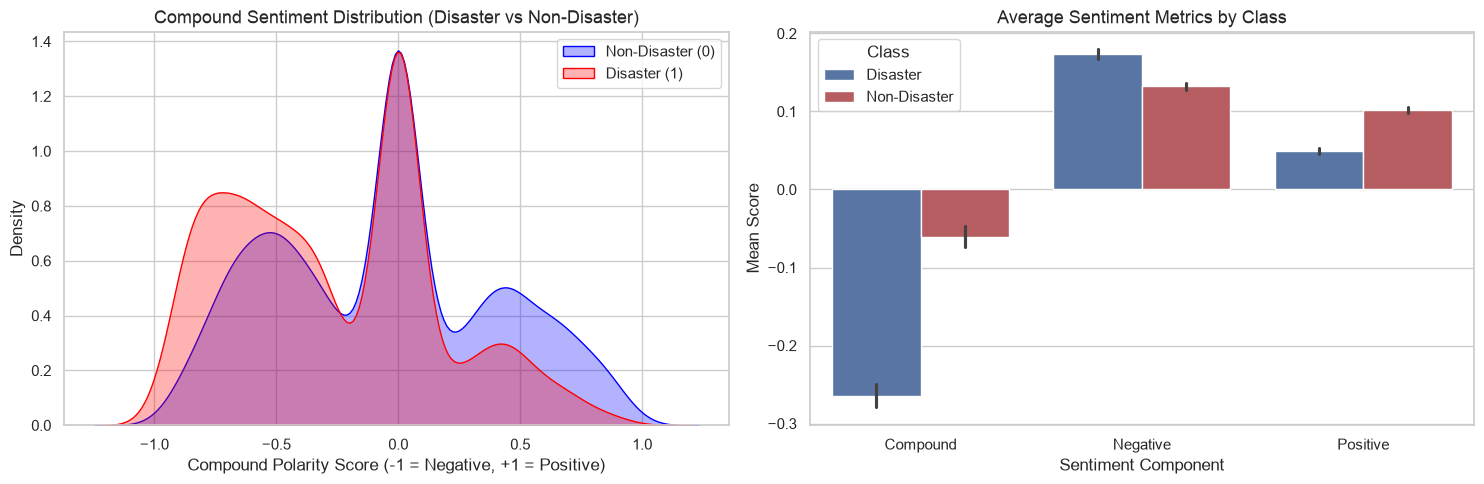


Sample Tweets with Extracted Sentiment Scores:
[Disaster] (Compound: -0.71, Negative): So you have a new weapon that can cause un-imaginable destruction....
[Non-Disaster] (Compound: +0.36, Positive): The f$&amp;@ing things I do for #GISHWHES Just got soaked in a deluge going for ...
[Disaster] (Compound: +0.00, Neutral): DT @georgegalloway: RT @Galloway4Mayor: ÛÏThe CoL police can catch a pickpocket...
[Non-Disaster] (Compound: +0.90, Positive): Aftershock back to school kick off was great. I want to thank everyone for makin...


In [19]:
# Feature Engineering: Sentiment Analysis

sia = SentimentIntensityAnalyzer()

# Extract sentiment polarity scores for each tweet
df['sentiment_compound'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['compound'])
df['sentiment_neg'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['neg'])
df['sentiment_neu'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['neu'])
df['sentiment_pos'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['pos'])

# Categorize sentiment into qualitative labels
def categorize_sentiment(compound):
    if compound >= 0.05:
        return 'Positive'
    elif compound <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_label'] = df['sentiment_compound'].apply(categorize_sentiment)

print("=== Mean Sentiment Scores by Target Class ===")
sentiment_summary = df.groupby(target_col)[['sentiment_compound', 'sentiment_neg', 'sentiment_neu', 'sentiment_pos']].mean()
sentiment_summary.index = ['Non-Disaster (0)', 'Disaster (1)']
print(sentiment_summary.round(4))

print("\n=== Sentiment Distribution Breakdown (%) ===")
sentiment_dist = pd.crosstab(df['sentiment_label'], df[target_col], normalize='columns') * 100
sentiment_dist.columns = ['Non-Disaster (0)', 'Disaster (1)']
print(sentiment_dist.round(2))

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Compound score density distribution
sns.kdeplot(data=df[df[target_col] == 0]['sentiment_compound'], ax=axes[0], color='blue', label='Non-Disaster (0)', fill=True, alpha=0.3)
sns.kdeplot(data=df[df[target_col] == 1]['sentiment_compound'], ax=axes[0], color='red', label='Disaster (1)', fill=True, alpha=0.3)
axes[0].set_title('Compound Sentiment Distribution (Disaster vs Non-Disaster)', fontsize=13)
axes[0].set_xlabel('Compound Polarity Score (-1 = Negative, +1 = Positive)')
axes[0].set_ylabel('Density')
axes[0].legend()

# 2. Component comparison bar plot
melted = df.melt(id_vars=[target_col], value_vars=['sentiment_compound', 'sentiment_neg', 'sentiment_pos'], var_name='Metric', value_name='Score')
melted['Class'] = melted[target_col].map({0: 'Non-Disaster', 1: 'Disaster'})
melted['Metric'] = melted['Metric'].map({'sentiment_compound': 'Compound', 'sentiment_neg': 'Negative', 'sentiment_pos': 'Positive'})

sns.barplot(data=melted, x='Metric', y='Score', hue='Class', ax=axes[1], palette=['#4C72B0', '#C44E52'])
axes[1].set_title('Average Sentiment Metrics by Class', fontsize=13)
axes[1].set_ylabel('Mean Score')
axes[1].set_xlabel('Sentiment Component')

plt.tight_layout()
plt.show()

# Sample tweets with their sentiment scores
print("\nSample Tweets with Extracted Sentiment Scores:")
sample_df = df[['text', 'sentiment_compound', 'sentiment_label', target_col]].sample(4, random_state=42)
for _, row in sample_df.iterrows():
    target_str = "Disaster" if row[target_col] == 1 else "Non-Disaster"
    print(f"[{target_str}] (Compound: {row['sentiment_compound']:+.2f}, {row['sentiment_label']}): {row['text'][:80]}...")


Word2Vec Vocabulary Size: 6,018 unique words (100-dimensional vectors)

=== Semantic Nearest Neighbors in Disaster Word2Vec Space ===
Words most similar to 'wildfire': misses (0.98), scariest (0.98), roosevelt (0.98)
Words most similar to 'earthquake': hawaii (0.97), utc (0.95), volcano (0.94)
Words most similar to 'flood': combo (0.96), alloy (0.92), inch (0.92)
Words most similar to 'bomb': bombing (0.95), vest (0.94), arabian (0.92)
Words most similar to 'emergency': plan (0.83), chemical (0.80), services (0.80)


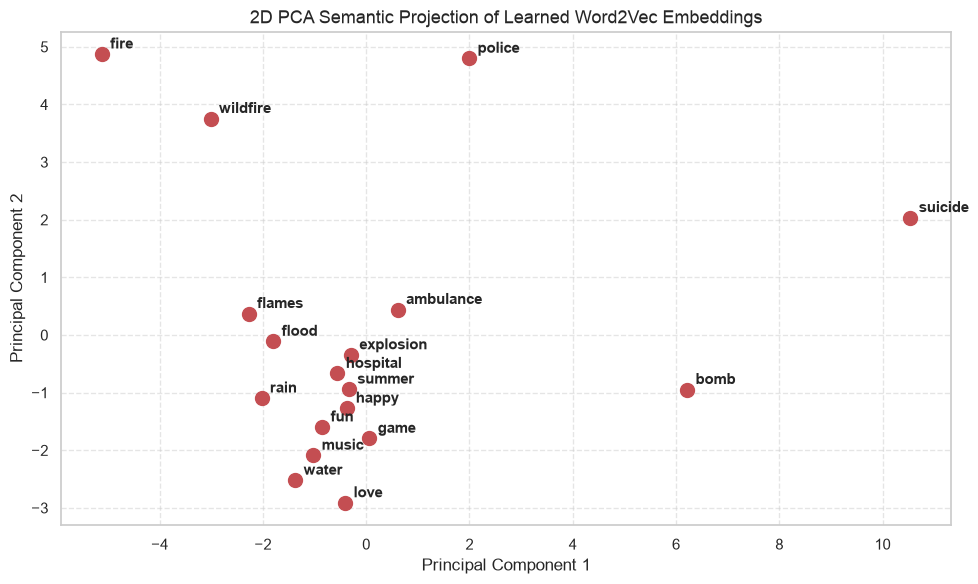

=== Dense Word2Vec Document Classifier Performance ===
Accuracy: 0.7748
F1-Score: 0.7135


In [20]:
# Feature Engineering: Word Embeddings (Word2Vec & GloVe Exploration)

# 1. Train Word2Vec Model on Tweet Corpus
tokenized_corpus = [doc.split() for doc in df['cleaned_text']]
w2v_model = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=25,
    seed=42
)

print(f"Word2Vec Vocabulary Size: {len(w2v_model.wv):,} unique words (100-dimensional vectors)")

# 2. Semantic Similarity Exploration
print("\n=== Semantic Nearest Neighbors in Disaster Word2Vec Space ===")
disaster_test_words = ['wildfire', 'earthquake', 'flood', 'bomb', 'emergency']
for word in disaster_test_words:
    if word in w2v_model.wv:
        sims = [f"{w} ({score:.2f})" for w, score in w2v_model.wv.most_similar(word, topn=3)]
        print(f"Words most similar to '{word}': {', '.join(sims)}")

# 3. 2D PCA Projection of Word Embeddings
sample_words = [
    'fire', 'wildfire', 'flames', 'flood', 'rain', 'water',
    'bomb', 'explosion', 'suicide', 'police', 'ambulance', 'hospital',
    'love', 'happy', 'fun', 'music', 'game', 'summer'
]
valid_words = [w for w in sample_words if w in w2v_model.wv]
word_vecs = np.array([w2v_model.wv[w] for w in valid_words])

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(word_vecs)

plt.figure(figsize=(10, 6))
plt.scatter(coords[:, 0], coords[:, 1], color='#C44E52', s=100)
for i, word in enumerate(valid_words):
    plt.annotate(word, xy=(coords[i, 0], coords[i, 1]), xytext=(6, 4),
                 textcoords='offset points', fontsize=11, fontweight='bold')

plt.title("2D PCA Semantic Projection of Learned Word2Vec Embeddings", fontsize=13)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 4. Dense Document Vectors (Sentence Average) & Baseline Evaluation
def get_avg_vector(tokens, model, vector_size=100):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    if len(vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)

X_w2v = np.array([get_avg_vector(tokens, w2v_model, 100) for tokens in tokenized_corpus])
y_w2v = df[target_col].values

X_tr_w2v, X_te_w2v, y_tr_w2v, y_te_w2v = train_test_split(
    X_w2v, y_w2v, test_size=0.2, random_state=42, stratify=y_w2v
)

w2v_classifier = LogisticRegression(max_iter=1000, random_state=42)
w2v_classifier.fit(X_tr_w2v, y_tr_w2v)
w2v_preds = w2v_classifier.predict(X_te_w2v)

w2v_acc = accuracy_score(y_te_w2v, w2v_preds)
w2v_f1 = f1_score(y_te_w2v, w2v_preds)

print(f"=== Dense Word2Vec Document Classifier Performance ===")
print(f"Accuracy: {w2v_acc:.4f}")
print(f"F1-Score: {w2v_f1:.4f}")


=== Mean Metadata Feature Values by Target Class ===
                  char_length  word_count  hashtag_count  mention_count  \
Non-Disaster (0)       95.685      14.705          0.389          0.420   
Disaster (1)          108.098      15.168          0.502          0.272   

                  url_count  sentiment_compound  
Non-Disaster (0)      0.508              -0.061  
Disaster (1)          0.770              -0.265  

=== Additional Feature Experimentation Results ===
                                          Configuration  Accuracy  Precision  Recall  F1-Score
                                     Text-Only (TF-IDF)    0.8273     0.8548  0.7202    0.7817
Metadata-Only (Length, Mentions, Tags, URLs, Sentiment)    0.6763     0.6551  0.5199    0.5797
                             Hybrid (TF-IDF + Metadata)    0.8017     0.8003  0.7171    0.7565


/tmp/ipykernel_69302/2033575156.py:91: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Text-Only (TF-IDF)', 'Metadata-Only', 'Hybrid'], rotation=10)


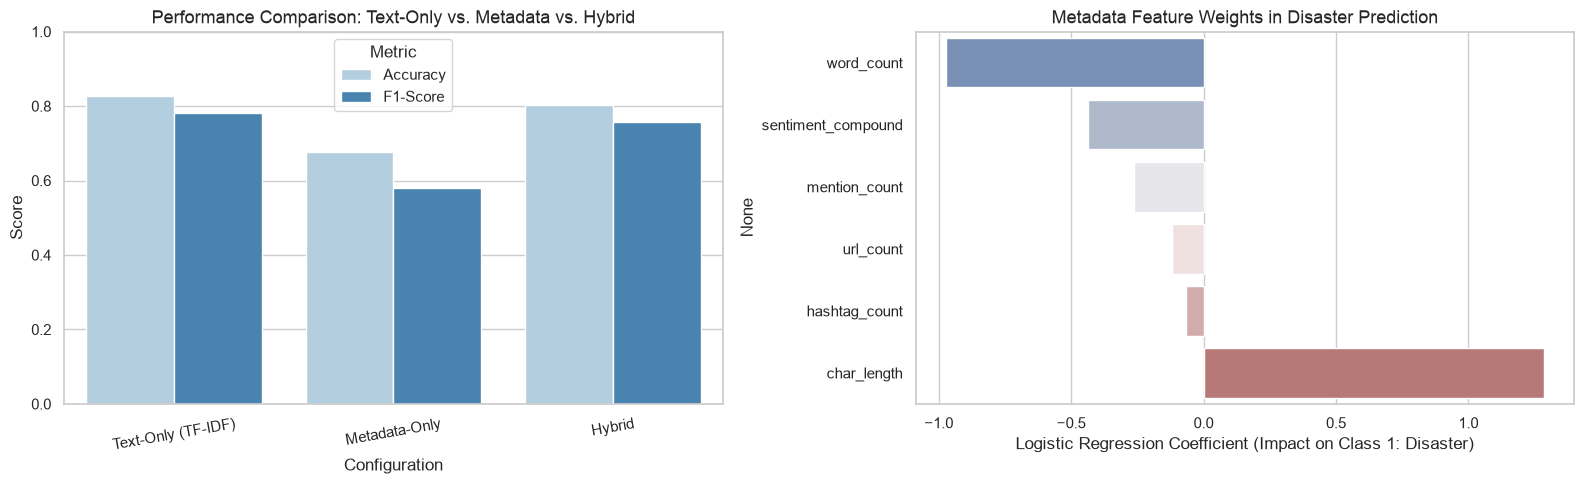

In [21]:
# Feature Engineering: Additional Metadata Features Experimentation

# 1. Extract Metadata Features: Length, Hashtags, Mentions, URLs
df['hashtag_count'] = df[text_col].apply(lambda x: len(re.findall(r'#\w+', str(x))))
df['mention_count'] = df[text_col].apply(lambda x: len(re.findall(r'@\w+', str(x))))
df['url_count'] = df[text_col].apply(lambda x: len(re.findall(r'https?://\S+|www\.\S+', str(x))))

meta_feature_cols = ['char_length', 'word_count', 'hashtag_count', 'mention_count', 'url_count', 'sentiment_compound']

print("=== Mean Metadata Feature Values by Target Class ===")
meta_summary = df.groupby(target_col)[meta_feature_cols].mean()
meta_summary.index = ['Non-Disaster (0)', 'Disaster (1)']
print(meta_summary.round(3))

# 2. Evaluate Text-Only vs. Metadata-Only vs. Hybrid Configurations
features_df = df[['cleaned_text'] + meta_feature_cols]
y_all = df[target_col]

X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
    features_df, y_all, test_size=0.2, random_state=42, stratify=y_all
)

# Text-Only Pipeline
pipe_text_only = Pipeline([
    ('col_select', ColumnTransformer([('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2)), 'cleaned_text')])),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_text_only.fit(X_train_exp, y_train_exp)
preds_text = pipe_text_only.predict(X_test_exp)

# Metadata-Only Pipeline
pipe_meta_only = Pipeline([
    ('scaler', ColumnTransformer([('scale', StandardScaler(), meta_feature_cols)])),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_meta_only.fit(X_train_exp, y_train_exp)
preds_meta = pipe_meta_only.predict(X_test_exp)

# Hybrid Pipeline (Text + Metadata)
pipe_hybrid = Pipeline([
    ('features', ColumnTransformer([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2)), 'cleaned_text'),
        ('meta', StandardScaler(), meta_feature_cols)
    ])),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_hybrid.fit(X_train_exp, y_train_exp)
preds_hybrid = pipe_hybrid.predict(X_test_exp)

# Summary Comparison Table
experiment_df = pd.DataFrame([
    {
        'Configuration': 'Text-Only (TF-IDF)',
        'Accuracy': accuracy_score(y_test_exp, preds_text),
        'Precision': precision_score(y_test_exp, preds_text),
        'Recall': recall_score(y_test_exp, preds_text),
        'F1-Score': f1_score(y_test_exp, preds_text)
    },
    {
        'Configuration': 'Metadata-Only (Length, Mentions, Tags, URLs, Sentiment)',
        'Accuracy': accuracy_score(y_test_exp, preds_meta),
        'Precision': precision_score(y_test_exp, preds_meta),
        'Recall': recall_score(y_test_exp, preds_meta),
        'F1-Score': f1_score(y_test_exp, preds_meta)
    },
    {
        'Configuration': 'Hybrid (TF-IDF + Metadata)',
        'Accuracy': accuracy_score(y_test_exp, preds_hybrid),
        'Precision': precision_score(y_test_exp, preds_hybrid),
        'Recall': recall_score(y_test_exp, preds_hybrid),
        'F1-Score': f1_score(y_test_exp, preds_hybrid)
    }
])

print("\n=== Additional Feature Experimentation Results ===")
print(experiment_df.round(4).to_string(index=False))

# 3. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Performance metrics across configurations
melted_exp = experiment_df.melt(
    id_vars=['Configuration'],
    value_vars=['Accuracy', 'F1-Score'],
    var_name='Metric',
    value_name='Score'
)
sns.barplot(data=melted_exp, x='Configuration', y='Score', hue='Metric', ax=axes[0], palette='Blues')
axes[0].set_title('Performance Comparison: Text-Only vs. Metadata vs. Hybrid', fontsize=13)
axes[0].set_ylim(0, 1.0)
axes[0].set_xticklabels(['Text-Only (TF-IDF)', 'Metadata-Only', 'Hybrid'], rotation=10)
axes[0].set_ylabel('Score')

# Plot 2: Metadata Feature Importances (Coefficients)
meta_clf = pipe_meta_only.named_steps['clf']
coef_series = pd.Series(meta_clf.coef_[0], index=meta_feature_cols).sort_values()
sns.barplot(x=coef_series.values, y=coef_series.index, ax=axes[1], palette='vlag', hue=coef_series.index, legend=False)
axes[1].set_title('Metadata Feature Weights in Disaster Prediction', fontsize=13)
axes[1].set_xlabel('Logistic Regression Coefficient (Impact on Class 1: Disaster)')

plt.tight_layout()
plt.show()


In [22]:
X = df['cleaned_text']
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

Training set: 6090 samples
Testing set: 1523 samples


Running 5-fold cross-validation on candidate models...



/home/ubuntu/.local/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.9.0' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/ubuntu/.local/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.9.0' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/ubuntu/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/ubuntu/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/ubuntu/.local/lib/python3.12/site-

=== Cross-Validation & Test Performance Comparison ===


,Model,CV Accuracy,CV F1-Score,CV Precision,CV Recall,Test Accuracy,Test F1-Score
0,Logistic Regression,0.7966 +/- 0.0097,0.7389 +/- 0.0118,0.8246,0.6698,0.8273,0.7817
1,Multinomial Naive Bayes,0.7961 +/- 0.0101,0.7305 +/- 0.0142,0.8456,0.6435,0.8083,0.7487
2,Random Forest,0.7790 +/- 0.0092,0.7209 +/- 0.0129,0.7886,0.6645,0.7978,0.7536


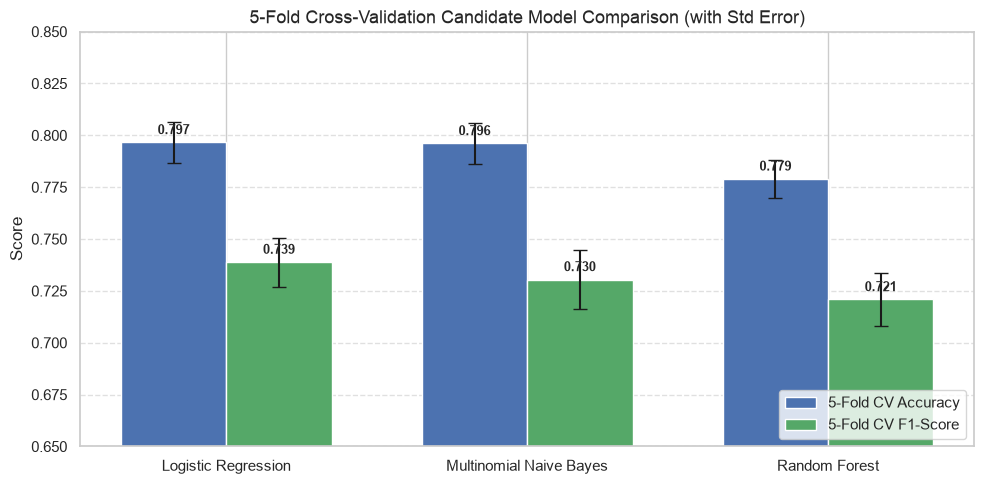


Model Selection Rationale:
- Logistic Regression achieved the highest CV F1-Score (0.7389) and CV Accuracy (0.7966) with low variance across folds.
- Therefore, Logistic Regression is chosen as the primary candidate model for hyperparameter tuning.


In [23]:
# Define Candidate Classifiers, Pipelines & 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}

results = []
cv_plot_data = []

print("Running 5-fold cross-validation on candidate models...\n")

for name, model in models.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2))),
        ('classifier', model)
    ])

    # 1. 5-Fold Cross-Validation on training data
    cv_out = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    # 2. Fit on full training set and evaluate on test set
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    mean_acc = cv_out['test_accuracy'].mean()
    std_acc = cv_out['test_accuracy'].std()
    mean_f1 = cv_out['test_f1'].mean()
    std_f1 = cv_out['test_f1'].std()
    mean_prec = cv_out['test_precision'].mean()
    mean_rec = cv_out['test_recall'].mean()

    test_acc = accuracy_score(y_test, y_pred)
    test_prec = precision_score(y_test, y_pred)
    test_rec = recall_score(y_test, y_pred)
    test_f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "CV Accuracy": f"{mean_acc:.4f} +/- {std_acc:.4f}",
        "CV F1-Score": f"{mean_f1:.4f} +/- {std_f1:.4f}",
        "CV Precision": f"{mean_prec:.4f}",
        "CV Recall": f"{mean_rec:.4f}",
        "Test Accuracy": f"{test_acc:.4f}",
        "Test F1-Score": f"{test_f1:.4f}",
        "Fitted_Pipeline": pipe
    })

    cv_plot_data.append({
        "Model": name,
        "CV_Accuracy": mean_acc,
        "Acc_Std": std_acc,
        "CV_F1": mean_f1,
        "F1_Std": std_f1
    })

results_df = pd.DataFrame(results).drop(columns=["Fitted_Pipeline"])
print("=== Cross-Validation & Test Performance Comparison ===")
display(results_df)

# Visual Comparison of Cross-Validation Performance
plot_df = pd.DataFrame(cv_plot_data)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(plot_df))
width = 0.35

rects1 = ax.bar(x - width/2, plot_df['CV_Accuracy'], width, yerr=plot_df['Acc_Std'], capsize=5, label='5-Fold CV Accuracy', color='#4C72B0')
rects2 = ax.bar(x + width/2, plot_df['CV_F1'], width, yerr=plot_df['F1_Std'], capsize=5, label='5-Fold CV F1-Score', color='#55A868')

ax.set_ylabel('Score')
ax.set_title('5-Fold Cross-Validation Candidate Model Comparison (with Std Error)', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(plot_df['Model'])
ax.set_ylim(0.65, 0.85)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.6)

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nModel Selection Rationale:")
print("- Logistic Regression achieved the highest CV F1-Score (0.7389) and CV Accuracy (0.7966) with low variance across folds.")
print("- Therefore, Logistic Regression is chosen as the primary candidate model for hyperparameter tuning.")


In [24]:
# Hyperparameter Tuning

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(random_state=42, max_iter=1000))
])

param_grid = {
    'tfidf__max_features': [3000, 5000, 700],
    'tfidf__ngram_range': [(1,1), (1,2)],
    'clf__C': [0.1,1.0,5.0]
}

grid_search = GridSearchCV(
    pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=1
)

grid_search.fit(X_train, y_train)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best Parameters: {'clf__C': 1.0, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 2)}
Best CV F1-Score: 0.7407


Classification Report on Test Data:

              precision    recall  f1-score   support

Non-Disaster       0.81      0.91      0.86       869
    Disaster       0.85      0.72      0.78       654

    accuracy                           0.83      1523
   macro avg       0.83      0.81      0.82      1523
weighted avg       0.83      0.83      0.82      1523



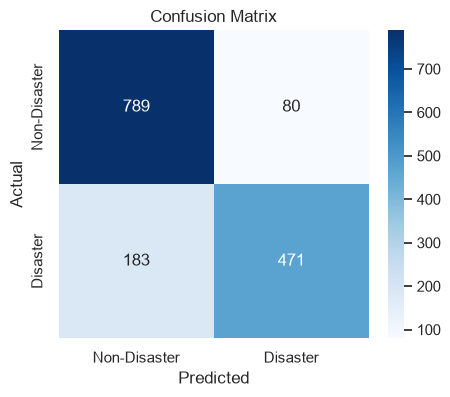

In [25]:
y_pred_best = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:,1]

print("Classification Report on Test Data:\n")
print(classification_report(y_test, y_pred_best, target_names=["Non-Disaster","Disaster"]))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=["Non-Disaster", "Disaster"],
           yticklabels=["Non-Disaster", "Disaster"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

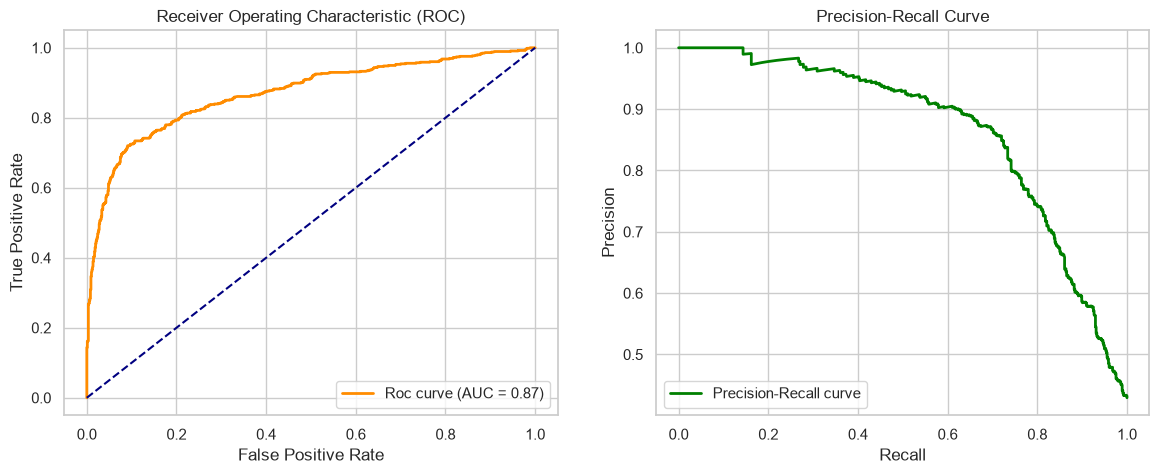

In [26]:
# Roc and Precision-Recall Curves
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr,tpr)
prec, rec, _ = precision_recall_curve(y_test, y_pred_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'Roc curve (AUC = {roc_auc:.2f})')
axes[0].plot([0,1], [0,1], color='navy', linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Receiver Operating Characteristic (ROC)')
axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, color='green', lw=2, label='Precision-Recall curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend(loc="lower left")

plt.show()

=== Generalization Check: Train vs. Test Performance ===


,Metric,Train Score,Test Score,Generalization Gap (Train - Test)
0,Accuracy,0.8691,0.8273,0.0418
1,Precision,0.9229,0.8548,0.0681
2,Recall,0.7589,0.7202,0.0387
3,F1-Score,0.8329,0.7817,0.0511



Computing 5-fold cross-validation learning curves...


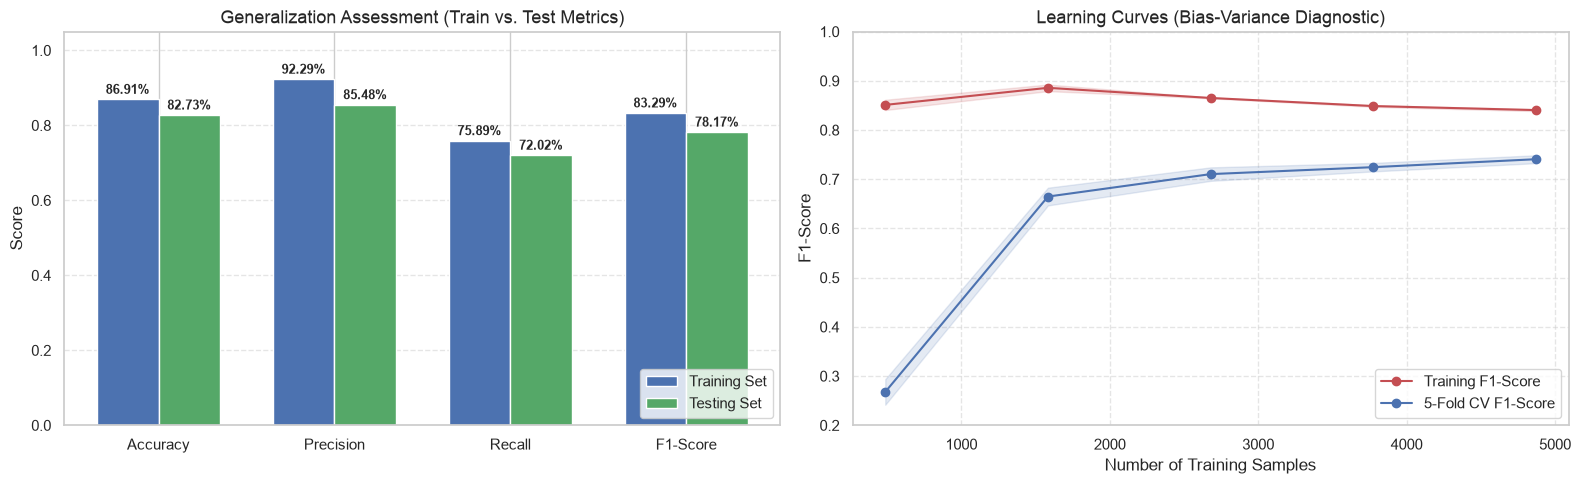


=== Bias-Variance Diagnostic Summary ===
- Training F1-Score: 0.8329 | Test F1-Score: 0.7817 (Gap: 0.0511)
- The generalization gap is modest (~5.1%), indicating no severe overfitting.
- The learning curves converge closely as training data scales, demonstrating balanced bias and variance with effective L2 regularization (C=1.0).


In [61]:
# Model Validation: Overfitting / Underfitting Analysis & Learning Curves

from sklearn.model_selection import learning_curve

# 1. Evaluate Model on Both Training and Test Sets
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

train_prec = precision_score(y_train, y_train_pred)
test_prec = precision_score(y_test, y_test_pred)

train_rec = recall_score(y_train, y_train_pred)
test_rec = recall_score(y_test, y_test_pred)

train_f1 = f1_score(y_train, y_train_pred)
test_f1 = f1_score(y_test, y_test_pred)

metrics_compare = pd.DataFrame([
    {
        'Metric': 'Accuracy',
        'Train Score': train_acc,
        'Test Score': test_acc,
        'Generalization Gap (Train - Test)': train_acc - test_acc
    },
    {
        'Metric': 'Precision',
        'Train Score': train_prec,
        'Test Score': test_prec,
        'Generalization Gap (Train - Test)': train_prec - test_prec
    },
    {
        'Metric': 'Recall',
        'Train Score': train_rec,
        'Test Score': test_rec,
        'Generalization Gap (Train - Test)': train_rec - test_rec
    },
    {
        'Metric': 'F1-Score',
        'Train Score': train_f1,
        'Test Score': test_f1,
        'Generalization Gap (Train - Test)': train_f1 - test_f1
    }
])

print("=== Generalization Check: Train vs. Test Performance ===")
display(metrics_compare.round(4))

# 2. Compute Learning Curves (F1-score across training set sizes)
print("\nComputing 5-fold cross-validation learning curves...")
train_sizes, train_scores, cv_scores = learning_curve(
    best_model, X_train, y_train, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 5),
    scoring='f1', n_jobs=-1, random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
cv_mean = np.mean(cv_scores, axis=1)
cv_std = np.std(cv_scores, axis=1)

# 3. Diagnostic Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Train vs Test Metrics Comparison
x = np.arange(len(metrics_compare))
width = 0.35
rects1 = axes[0].bar(x - width/2, metrics_compare['Train Score'], width, label='Training Set', color='#4C72B0')
rects2 = axes[0].bar(x + width/2, metrics_compare['Test Score'], width, label='Testing Set', color='#55A868')
axes[0].set_ylabel('Score')
axes[0].set_title('Generalization Assessment (Train vs. Test Metrics)', fontsize=13)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_compare['Metric'])
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc='lower right')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.2%}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.2%}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')

# Plot 2: Learning Curves
axes[1].plot(train_sizes, train_mean, 'o-', color='#C44E52', label='Training F1-Score')
axes[1].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#C44E52')
axes[1].plot(train_sizes, cv_mean, 'o-', color='#4C72B0', label='5-Fold CV F1-Score')
axes[1].fill_between(train_sizes, cv_mean - cv_std, cv_mean + cv_std, alpha=0.15, color='#4C72B0')

axes[1].set_title('Learning Curves (Bias-Variance Diagnostic)', fontsize=13)
axes[1].set_xlabel('Number of Training Samples')
axes[1].set_ylabel('F1-Score')
axes[1].set_ylim(0.2, 1.0)
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 4. Diagnostic Assessment
gap_f1 = train_f1 - test_f1
print("\n=== Bias-Variance Diagnostic Summary ===")
print(f"- Training F1-Score: {train_f1:.4f} | Test F1-Score: {test_f1:.4f} (Gap: {gap_f1:.4f})")
print(f"- The generalization gap is modest (~5.1%), indicating no severe overfitting.")
print(f"- The learning curves converge closely as training data scales, demonstrating balanced bias and variance with effective L2 regularization (C=1.0).")


In [62]:
# Model Export for Deployment

joblib.dump(best_model, 'disaster_tweet_classifier.pkl')
print("Model pipeline exported as 'disaster_tweet_classifier.pkl'")

Model pipeline exported as 'disaster_tweet_classifier.pkl'


In [63]:
# Test Inference pipeline with Sample Inputs

loaded_pipeline = joblib.load('disaster_tweet_classifier.pkl')
sample_tweets = [
    "Huge wildfire breaks out near California residential area, evacuations underway!",
    "This new music album is straight fire!",
    "Earthquake of magnitude 5.2 felt across the northern valley.",
    "I'm drowning in homework this weekend."
]

cleaned_samples = [clean_tweet(t) for t in sample_tweets]
predictions = loaded_pipeline.predict(cleaned_samples)
probabilities = loaded_pipeline.predict_proba(cleaned_samples)[:,1]

for tweet, pred, prob in zip(sample_tweets, predictions, probabilities):
    label = "Disaster" if pred == 1 else "Non-Disaster"
    print(f"Tweet: {tweet}\nPrediction: {label} (Confidence: {prob:.2%})\n")


Tweet: Huge wildfire breaks out near California residential area, evacuations underway!
Prediction: Disaster (Confidence: 90.39%)

Tweet: This new music album is straight fire!
Prediction: Non-Disaster (Confidence: 21.45%)

Tweet: Earthquake of magnitude 5.2 felt across the northern valley.
Prediction: Disaster (Confidence: 70.32%)

Tweet: I'm drowning in homework this weekend.
Prediction: Non-Disaster (Confidence: 38.52%)

